In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
data = pd.read_csv("../data/trajectories.csv")
# display(data)
display(data.dtypes)


time           float64
particle_id      int64
x              float64
y              float64
dtype: object

In [3]:
x = data.pivot(
    index = "particle_id",
    columns = "time",
    values = "x"
)

y = data.pivot(
    index = "particle_id",
    columns = "time",
    values = "y"
)

x0 = x.iloc[:, 0].to_numpy().reshape(-1, 1)     # column vector
y0 = y.iloc[:, 0].to_numpy().reshape(-1, 1)     # -1 = auto

times = x.columns.to_numpy()

msd = np.mean(
    (x.to_numpy() - x0)**2 +
    (y.to_numpy() - y0)**2,
    axis = 0
)


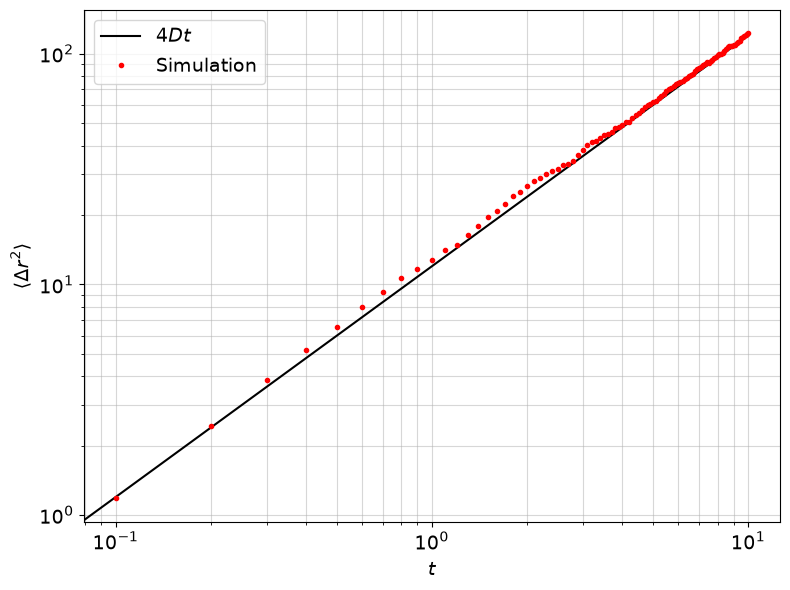

In [4]:
# fontsizes
fs_axes = 14
fs_ticks = 14
fs_legend = 14

# --- PLOT ---
fig, ax = plt.subplots(figsize=(8, 6))

D = 3
z = np.linspace(np.min(times), np.max(times), 5)
ax.plot(z, 4 * D * z, 'k-', label="$4Dt$")
ax.plot(times, msd, 'r.', label="Simulation")


ax.set_xlabel("$t$", fontsize=fs_axes)
ax.set_ylabel(r"$\langle \Delta r^2 \rangle$", fontsize=fs_axes)

ax.tick_params(labelsize=fs_ticks)

ax.set_xscale("log")
ax.set_yscale("log")
ax.grid(which="both", alpha=0.5)
ax.legend(fontsize=fs_legend)

fig.tight_layout()
plt.show()
